# Projeto Zuber — concorrentes, destinos e clima em Chicago

**Período analisado:** novembro de 2017.

Este projeto reúne a coleta dos registros meteorológicos, as consultas SQL,
a análise dos concorrentes e dos destinos e o teste sobre a duração das corridas
do Loop para o Aeroporto Internacional O'Hare aos sábados.

O teste específico usa **duração média**, conforme os passos 3 e 5 do enunciado.
Os arquivos disponíveis não permitem testar diretamente se a chuva altera a
frequência total de corridas na cidade.

## Como executar

Execute as células na ordem. O notebook procura os dados em `data/`, em
`/datasets/` e na pasta atual. Quando um arquivo está ausente, tenta baixá-lo da
fonte do curso. O pacote completo inclui os dados para execução sem conexão.

As consultas SQL devem ser executadas no banco do curso. Seus resultados não
foram recalculados aqui a partir das tabelas originais, às quais não há conexão.
Os CSVs oficiais permitem executar os passos 4 e 5.

## Fontes e estrutura dos dados

- [Registros meteorológicos indicados no enunciado](https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html).
- [project_sql_result_01.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/project_sql_result_01.csv): corridas por empresa em 15 e 16 de novembro.
- [project_sql_result_04.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/project_sql_result_04.csv): média de desembarques por bairro em novembro.
- [project_sql_result_07.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/project_sql_result_07.csv): corridas Loop → O'Hare aos sábados.
- [Documentação do teste `scipy.stats.ttest_ind`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).

Dados consultados em 07/10/2026. O esquema abaixo foi fornecido no anexo.

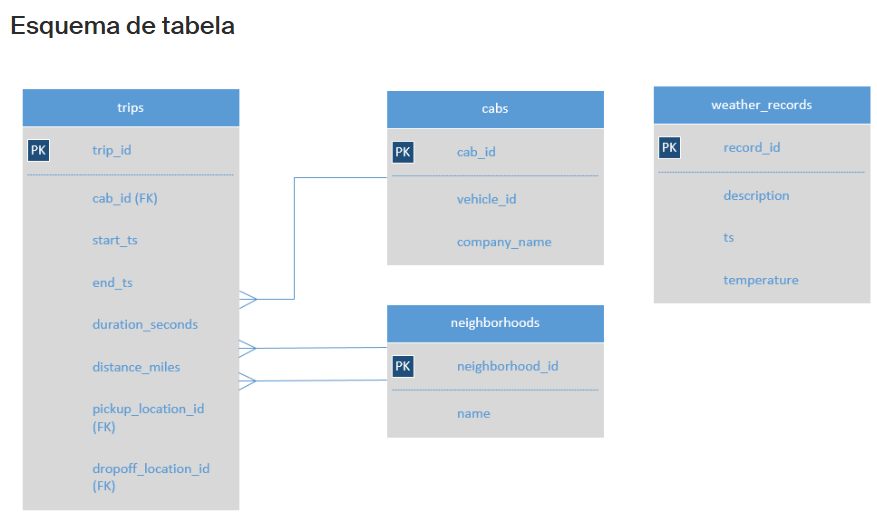

`trips.cab_id` conecta corridas a táxis. Os identificadores de retirada e entrega
conectam corridas aos bairros. O clima é associado pelo horário de início da
corrida: `trips.start_ts = weather_records.ts`.

In [1]:
from pathlib import Path
from io import StringIO
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

ALFA = 0.05  # Escolhido antes de observar os resultados do teste.
DATA_DIR = Path('data')
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)

URL_CLIMA = (
    'https://practicum-content.s3.us-west-1.amazonaws.com/'
    'data-analyst-eng/moved_chicago_weather_2017.html'
)
URL_DATASETS = 'https://practicum-content.s3.us-west-1.amazonaws.com/datasets/'

pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 2)
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlepad': 16,
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
})
AZUL = '#24445f'
VERDE = '#008d85'
LARANJA = '#d47b36'

def numero_pt(valor, casas=0):
    return f'{valor:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def obter_arquivo(nome, url):
    candidatos = [DATA_DIR / nome, Path('/datasets') / nome, Path(nome)]
    for caminho in candidatos:
        if caminho.is_file():
            return caminho
    DATA_DIR.mkdir(exist_ok=True)
    pedido = Request(url, headers={'User-Agent': 'Zuber academic analysis'})
    with urlopen(pedido, timeout=30) as resposta:
        conteudo = resposta.read()
    caminho = DATA_DIR / nome
    caminho.write_bytes(conteudo)
    return caminho

## Passo 1 — coleta e análise do clima

O código lê o HTML e extrai a tabela de ID `weather_records`, sem depender da
posição dela na página. Convertemos horários para `datetime`, temperatura para
número e descrições para texto. A unidade de temperatura não está informada no
enunciado e foi mantida como na fonte.

In [2]:
arquivo_clima = obter_arquivo('weather.html', URL_CLIMA)
conteudo_html = arquivo_clima.read_text(encoding='utf-8')
tabelas = pd.read_html(StringIO(conteudo_html), attrs={'id': 'weather_records'})
clima = tabelas[0].rename(columns={
    'Date and time': 'ts',
    'Temperature': 'temperature',
    'Description': 'description',
})
clima['ts'] = pd.to_datetime(clima['ts'], errors='raise')
clima['temperature'] = pd.to_numeric(clima['temperature'], errors='raise')
clima['description'] = clima['description'].astype('string').str.strip()
clima = clima.sort_values('ts').reset_index(drop=True)
if clima.isna().any().any():
    raise ValueError('Há campos ausentes nos registros meteorológicos.')
if clima['ts'].duplicated().any():
    raise ValueError('Há mais de um registro de clima para a mesma hora.')
clima['weather_conditions'] = np.where(
    clima['description'].str.contains('rain|storm', case=False, regex=True),
    'Bad', 'Good'
)
clima.head()

,ts,temperature,description,weather_conditions
0,2017-11-01 00:00:00,276.15,broken clouds,Good
1,2017-11-01 01:00:00,275.70,scattered clouds,Good
2,2017-11-01 02:00:00,275.61,overcast clouds,Good
3,2017-11-01 03:00:00,275.35,broken clouds,Good
4,2017-11-01 04:00:00,275.24,broken clouds,Good


In [3]:
horas_esperadas = pd.date_range(
    '2017-11-01', '2017-12-01', freq='h', inclusive='left'
)
horas_ausentes = horas_esperadas.difference(clima['ts'])
print(f'Registros disponíveis: {len(clima)}')
print(f'Período observado: {clima.ts.min()} a {clima.ts.max()}')
print(f'Horas sem registro no mês: {len(horas_ausentes)}')
if len(horas_ausentes):
    print(f'Intervalo ausente: {horas_ausentes.min()} a {horas_ausentes.max()}')
print('Tipos:', clima.dtypes.astype(str).to_dict())
print('Descrições mais frequentes:')
print(clima['description'].value_counts().head(5).to_string())
resumo_clima = (
    clima['weather_conditions'].value_counts().rename_axis('weather_conditions')
    .reset_index(name='horas_observadas')
)
resumo_clima['percentual_das_horas_observadas'] = (
    100 * resumo_clima['horas_observadas'] / len(clima)
)
resumo_clima

Registros disponíveis: 697
Período observado: 2017-11-01 00:00:00 a 2017-11-30 00:00:00
Horas sem registro no mês: 23
Intervalo ausente: 2017-11-30 01:00:00 a 2017-11-30 23:00:00
Tipos: {'ts': 'datetime64[ns]', 'temperature': 'float64', 'description': 'string', 'weather_conditions': 'object'}
Descrições mais frequentes:
description
sky is clear        178
overcast clouds     146
mist                 97
broken clouds        63
scattered clouds     47


,weather_conditions,horas_observadas,percentual_das_horas_observadas
0,Good,643,92.25
1,Bad,54,7.75


**Interpretação.** A fonte contém 697 registros, até 30/11 às 00h. Faltam os 23
horários seguintes desse dia. As horas ausentes não foram preenchidas.

`Bad` segue a regra literal do projeto: descrição contendo `rain` ou `storm`.
`Good` reúne as demais descrições e pode incluir garoa (`drizzle`), neve ou
neblina. Portanto, esses rótulos são categorias operacionais do enunciado.

## Passo 2 — análise exploratória em SQL

As consultas usam PostgreSQL. Em campos com data e hora, o limite superior
exclusivo evita perder as corridas do último dia do período.

### 2.1. Corridas por empresa em 15 e 16 de novembro

O JOIN relaciona a corrida à empresa pelo `cab_id`. A contagem é agrupada pelo nome da empresa.

```sql
-- PASSO 2.1: corridas por empresa em 15 e 16 de novembro.
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM trips AS t
INNER JOIN cabs AS c ON t.cab_id = c.cab_id
WHERE t.start_ts >= TIMESTAMP '2017-11-15 00:00:00'
  AND t.start_ts < TIMESTAMP '2017-11-17 00:00:00'
GROUP BY c.company_name
ORDER BY trips_amount DESC;
```

### 2.2. Empresas com Yellow ou Blue no nome, de 1 a 7 de novembro

Os parênteses preservam o filtro de datas para as duas alternativas. `LOWER` permite encontrar os nomes independentemente de maiúsculas.

```sql
-- PASSO 2.2: nomes que contêm Yellow ou Blue, de 1 a 7 de novembro.
SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM trips AS t
INNER JOIN cabs AS c ON t.cab_id = c.cab_id
WHERE t.start_ts >= TIMESTAMP '2017-11-01 00:00:00'
  AND t.start_ts < TIMESTAMP '2017-11-08 00:00:00'
  AND (
      LOWER(c.company_name) LIKE '%yellow%'
      OR LOWER(c.company_name) LIKE '%blue%'
  )
GROUP BY c.company_name
ORDER BY trips_amount DESC;
```

### 2.3. Flash Cab, Taxi Affiliation Services e Other em novembro

O CASE mantém as duas empresas nomeadas e reúne as demais em `Other`. O período é novembro inteiro.

```sql
-- PASSO 2.3: Flash Cab, Taxi Affiliation Services e Other no mês inteiro.
SELECT
    CASE
        WHEN c.company_name IN ('Flash Cab', 'Taxi Affiliation Services')
            THEN c.company_name
        ELSE 'Other'
    END AS company,
    COUNT(t.trip_id) AS trips_amount
FROM trips AS t
INNER JOIN cabs AS c ON t.cab_id = c.cab_id
WHERE t.start_ts >= TIMESTAMP '2017-11-01 00:00:00'
  AND t.start_ts < TIMESTAMP '2017-12-01 00:00:00'
GROUP BY company
ORDER BY trips_amount DESC;
```

## Passo 3 — preparação das corridas para o teste

O enunciado informa os IDs **50 para Loop** e **63 para O'Hare**. A primeira
consulta abaixo permite conferi-los no banco.

### 3.1. Identificadores dos bairros

O apóstrofo de O'Hare é escapado duplicando-o dentro da string SQL.

```sql
-- PASSO 3.1: identificadores dos bairros.
SELECT name, neighborhood_id
FROM neighborhoods
WHERE name IN ('Loop', 'O''Hare')
ORDER BY neighborhood_id;
```

### 3.2. Condição meteorológica por horário

A consulta retorna apenas `ts` e `weather_conditions`, conforme solicitado.

```sql
-- PASSO 3.2: classificação do clima na hora registrada.
SELECT
    ts,
    CASE
        WHEN LOWER(description) LIKE '%rain%'
          OR LOWER(description) LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions
FROM weather_records
ORDER BY ts;
```

### 3.3. Corridas do Loop para O'Hare aos sábados

O INNER JOIN exclui corridas sem horário correspondente no clima. `EXTRACT(DOW ...) = 6` seleciona sábado em PostgreSQL. O filtro de novembro mantém o escopo temporal do projeto.

```sql
-- PASSO 3.3: Loop → O'Hare, sábados de novembro, com clima disponível.
-- No PostgreSQL, EXTRACT(DOW ...) retorna 6 para sábado.
WITH weather_by_hour AS (
    SELECT
        ts,
        CASE
            WHEN LOWER(description) LIKE '%rain%'
              OR LOWER(description) LIKE '%storm%' THEN 'Bad'
            ELSE 'Good'
        END AS weather_conditions
    FROM weather_records
)
SELECT
    t.start_ts,
    w.weather_conditions,
    t.duration_seconds
FROM trips AS t
INNER JOIN weather_by_hour AS w ON t.start_ts = w.ts
WHERE t.pickup_location_id = 50
  AND t.dropoff_location_id = 63
  AND EXTRACT(DOW FROM t.start_ts) = 6
  AND t.start_ts >= TIMESTAMP '2017-11-01 00:00:00'
  AND t.start_ts < TIMESTAMP '2017-12-01 00:00:00'
ORDER BY t.start_ts;
```

### Verificação da chave de clima

Antes de executar o JOIN, confirme que há um registro meteorológico por `ts`.
Mais de um registro para a mesma hora pode multiplicar as corridas. A tabela
HTML fornecida tem horários únicos. Esta consulta verifica o banco do curso:

```sql
-- DIAGNÓSTICO: verificar a unicidade de ts antes de unir clima e corridas.
-- Resultado esperado: nenhuma linha. Repetições devem ser investigadas
-- antes do JOIN, pois podem multiplicar as corridas no resultado.
SELECT ts, COUNT(*) AS records_per_hour
FROM weather_records
GROUP BY ts
HAVING COUNT(*) > 1;
```

## Passo 4 — análise exploratória em Python

`project_sql_result_01.csv` é uma tabela agregada por empresa para dois dias.
`project_sql_result_04.csv` contém médias por bairro para novembro. Os períodos
e as medidas são diferentes e foram analisados separadamente.

In [4]:
empresas_original = pd.read_csv(obter_arquivo(
    'project_sql_result_01.csv', URL_DATASETS + 'project_sql_result_01.csv'
))
bairros_original = pd.read_csv(obter_arquivo(
    'project_sql_result_04.csv', URL_DATASETS + 'project_sql_result_04.csv'
))

for nome, df in [('Empresas', empresas_original), ('Bairros', bairros_original)]:
    print()
    print(f'{nome}: {df.shape[0]} linhas, {df.shape[1]} colunas')
    print(df.head().to_string(index=False))
    df.info()

diagnostico_eda = pd.DataFrame([
    {
        'base': nome,
        'linhas': len(df),
        'valores_ausentes': int(df.isna().sum().sum()),
        'linhas_repetidas': int(df.duplicated().sum()),
    }
    for nome, df in [('Empresas', empresas_original), ('Bairros', bairros_original)]
])
diagnostico_eda


Empresas: 64 linhas, 2 colunas
                   company_name  trips_amount
                      Flash Cab         19558
      Taxi Affiliation Services         11422
              Medallion Leasing         10367
                     Yellow Cab          9888
Taxi Affiliation Service Yellow          9299
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB

Bairros: 94 linhas, 2 colunas
dropoff_location_name  average_trips
                 Loop       10727.47
          River North        9523.67
        Streeterville        6664.67
            West Loop        5163.67
               O'Hare        2546.90
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column      

,base,linhas,valores_ausentes,linhas_repetidas
0,Empresas,64,0,0
1,Bairros,94,0,0


In [5]:
empresas = empresas_original.copy()
bairros = bairros_original.copy()
empresas['company_name'] = empresas['company_name'].astype('string').str.strip()
bairros['dropoff_location_name'] = (
    bairros['dropoff_location_name'].astype('string').str.strip()
)
empresas['trips_amount'] = pd.to_numeric(empresas['trips_amount'], errors='raise')
bairros['average_trips'] = pd.to_numeric(bairros['average_trips'], errors='raise')

for df, chave, valor in [
    (empresas, 'company_name', 'trips_amount'),
    (bairros, 'dropoff_location_name', 'average_trips'),
]:
    if df[[chave, valor]].isna().any().any() or df[chave].eq('').any():
        raise ValueError(f'Campos obrigatórios ausentes em {chave}.')
    if df[chave].duplicated().any():
        raise ValueError(f'Chave repetida na base agregada: {chave}.')
    if not np.isfinite(df[valor]).all() or df[valor].lt(0).any():
        raise ValueError(f'Valor inválido em {valor}.')

if not empresas['trips_amount'].mod(1).eq(0).all():
    raise ValueError('A contagem de corridas deve ser inteira.')
empresas['trips_amount'] = empresas['trips_amount'].astype('int64')
empresas = empresas.sort_values('trips_amount', ascending=False).reset_index(drop=True)
bairros = bairros.sort_values('average_trips', ascending=False).reset_index(drop=True)

print('Tipos finais das empresas:', empresas.dtypes.astype(str).to_dict())
print('Tipos finais dos bairros:', bairros.dtypes.astype(str).to_dict())
print('average_trips permanece decimal, pois representa uma média.')
empresas.describe()

Tipos finais das empresas: {'company_name': 'string', 'trips_amount': 'int64'}
Tipos finais dos bairros: {'dropoff_location_name': 'string', 'average_trips': 'float64'}
average_trips permanece decimal, pois representa uma média.


,trips_amount
count,64.00
mean,2145.48
std,3812.31
min,2.00
25%,20.75
50%,178.50
75%,2106.50
max,19558.00


### Empresas e número de corridas

O primeiro gráfico mostra todas as empresas. O segundo amplia as 15 primeiras
para facilitar a leitura dos maiores volumes. Ambos usam o mesmo período.

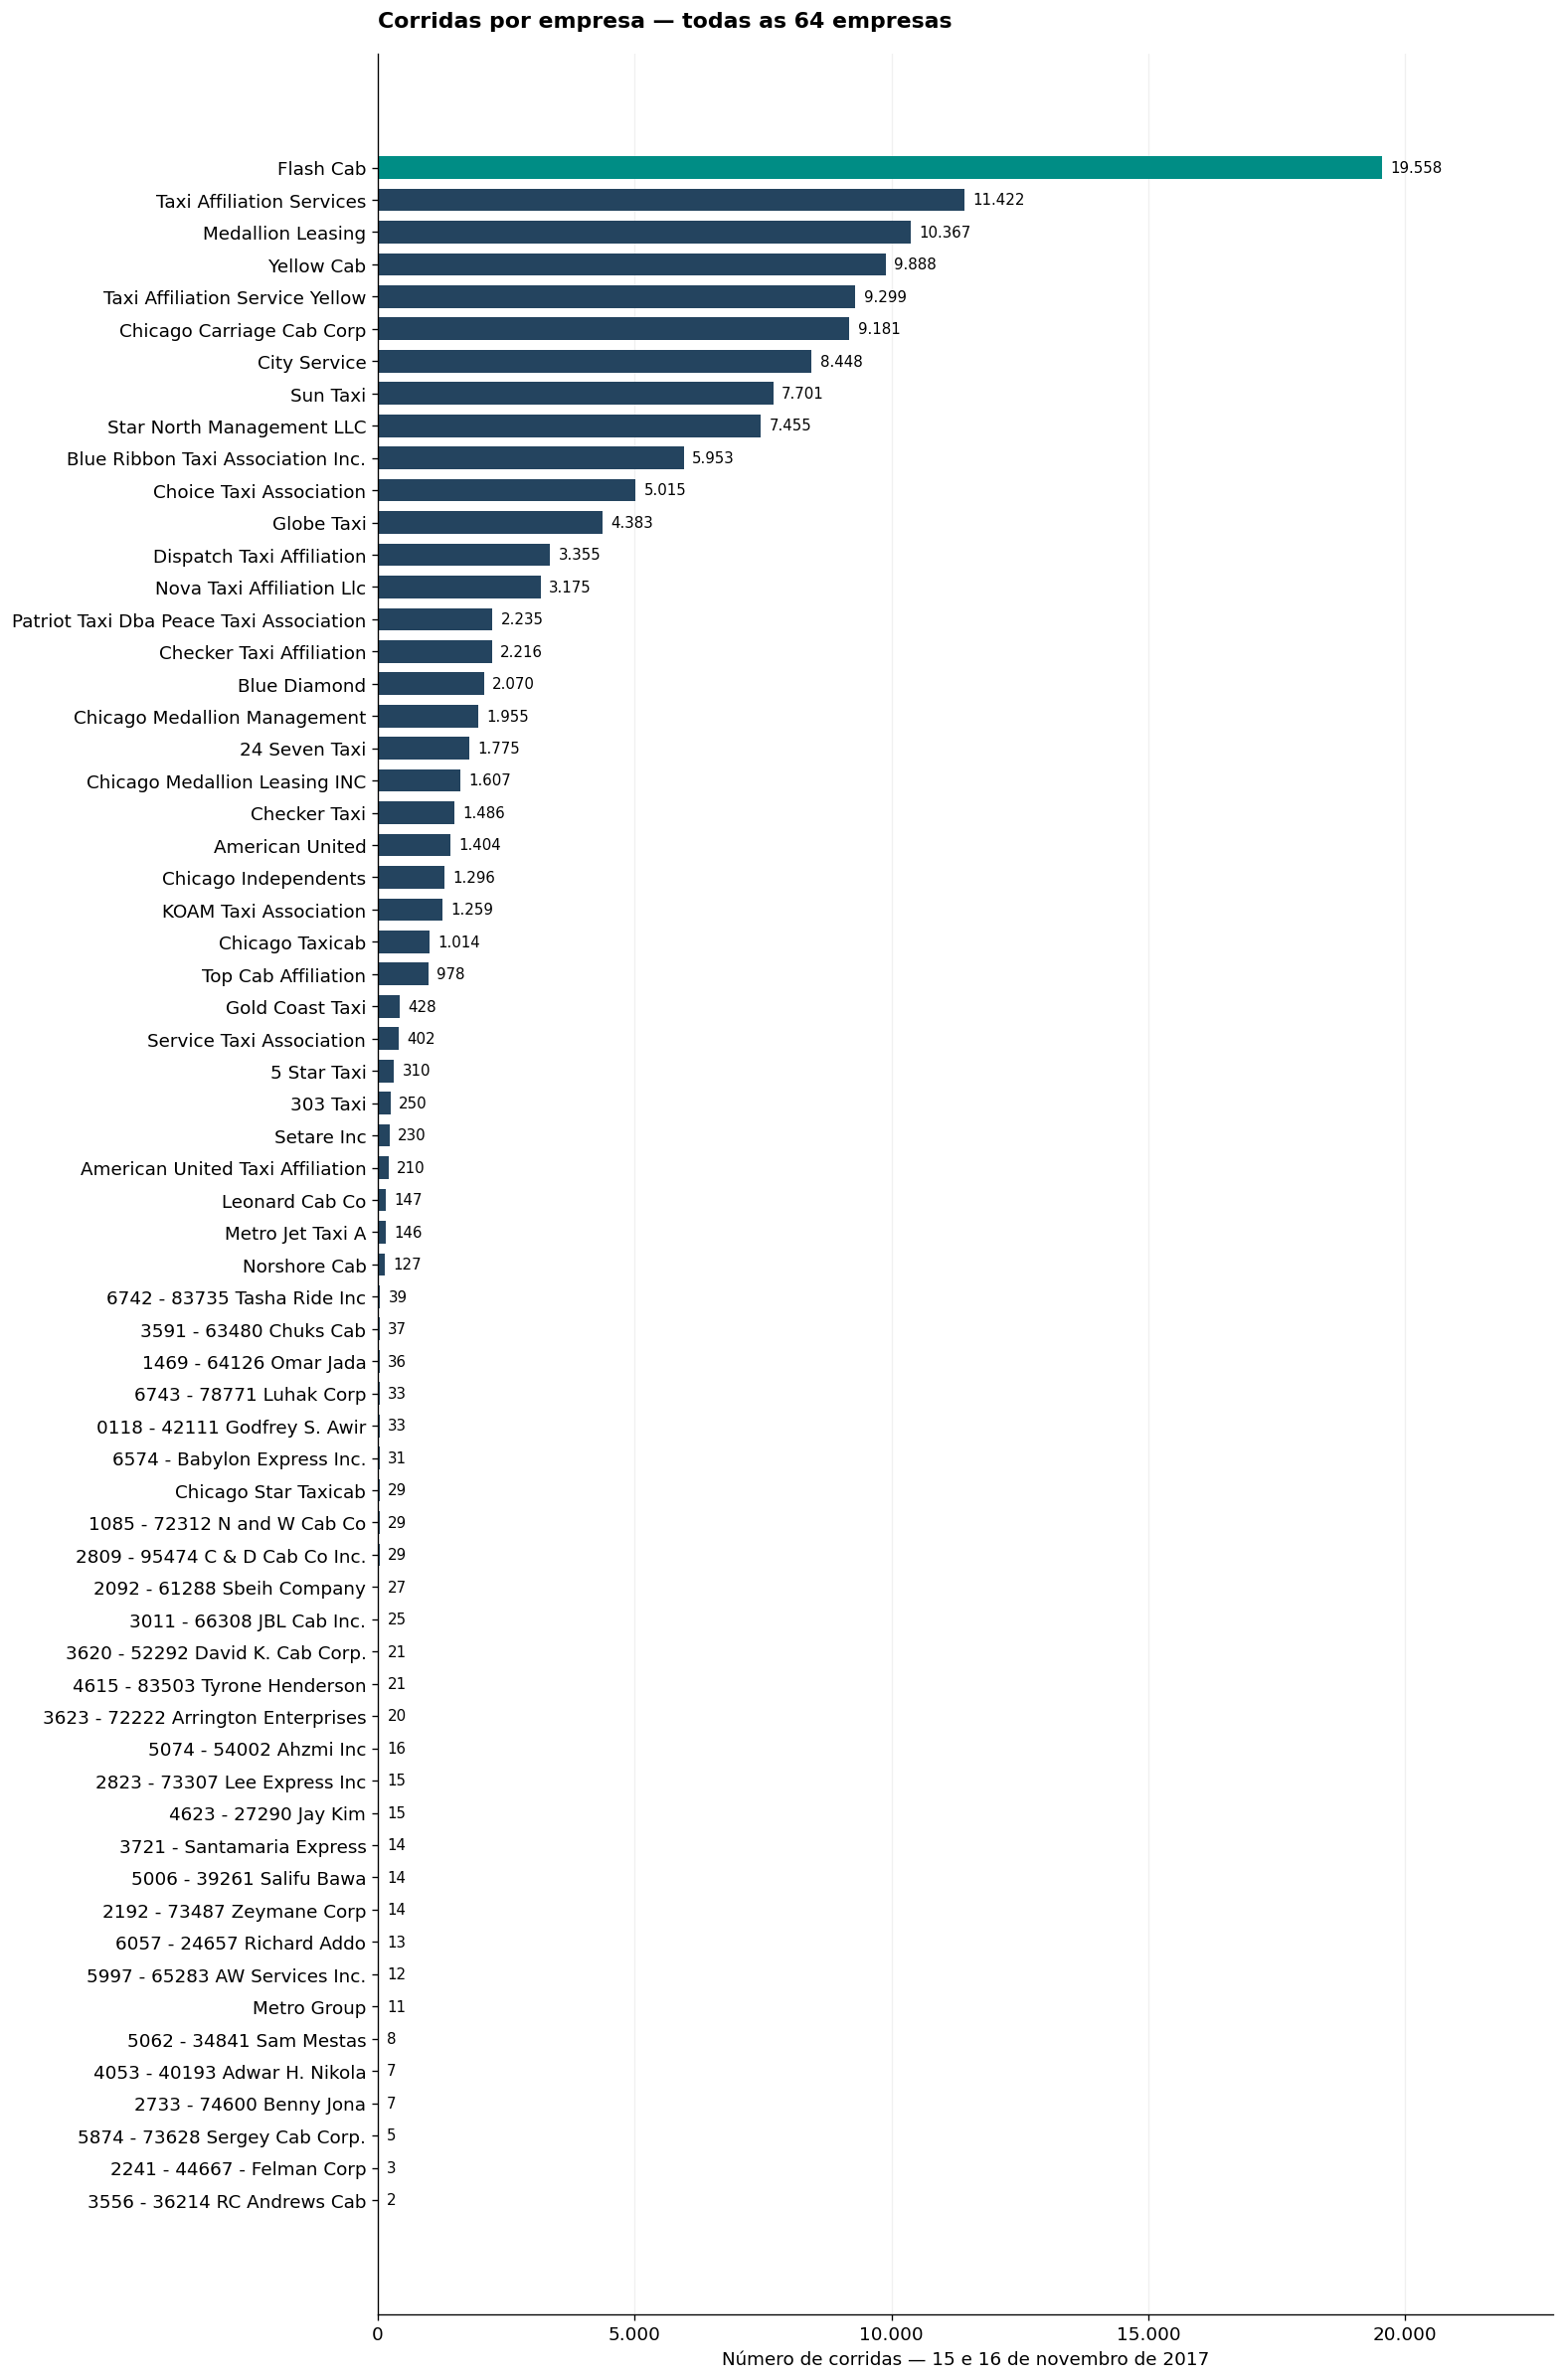

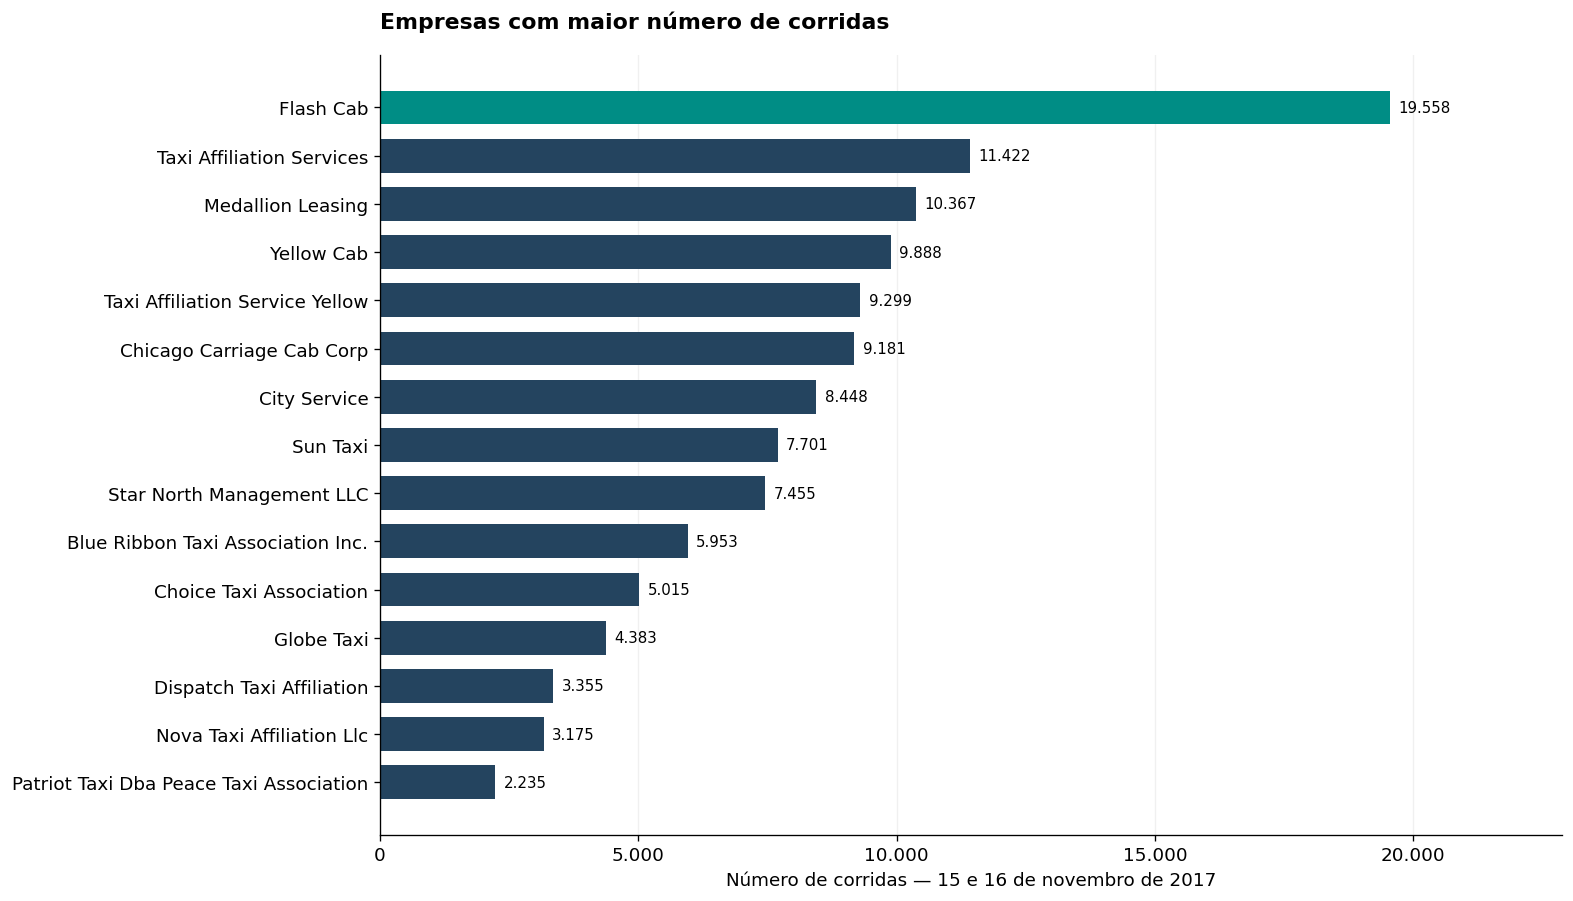

In [6]:
def grafico_empresas(dados, titulo, arquivo, altura):
    fig, ax = plt.subplots(figsize=(13, altura), layout='constrained')
    cores = [VERDE if nome == 'Flash Cab' else AZUL for nome in dados.company_name]
    barras = ax.barh(dados.company_name, dados.trips_amount, color=cores, height=0.7)
    ax.invert_yaxis()
    ax.set_title(titulo, loc='left')
    ax.set_xlabel('Número de corridas — 15 e 16 de novembro de 2017')
    ax.set_ylabel('')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: numero_pt(v)))
    ax.set_xlim(0, dados.trips_amount.max() * 1.17)
    ax.grid(axis='x', alpha=0.18)
    ax.set_axisbelow(True)
    ax.bar_label(barras, labels=[numero_pt(v) for v in dados.trips_amount],
                 padding=5, fontsize=9)
    fig.savefig(RESULTADOS / arquivo, dpi=140, bbox_inches='tight')
    plt.show()

grafico_empresas(empresas, 'Corridas por empresa — todas as 64 empresas',
                  'empresas_todas.png', max(9, 0.31 * len(empresas)))
grafico_empresas(empresas.head(15), 'Empresas com maior número de corridas',
                  'empresas_top15.png', 7.4)

In [7]:
total_corridas = int(empresas.trips_amount.sum())
lider = empresas.iloc[0]
segunda = empresas.iloc[1]
participacao_top10 = empresas.head(10).trips_amount.sum() / total_corridas
print(
    f'A base reúne {numero_pt(total_corridas)} corridas em {len(empresas)} empresas. '
    f'{lider.company_name} lidera com {numero_pt(lider.trips_amount)} corridas '
    f'({numero_pt(100 * lider.trips_amount / total_corridas, 2)}% da amostra). '
    f'{segunda.company_name} ocupa a segunda posição, com '
    f'{numero_pt(segunda.trips_amount)} corridas.'
)
print(
    f'As dez maiores empresas concentram '
    f'{numero_pt(100 * participacao_top10, 2)}% das corridas observadas.'
)
print(
    'A diferença entre os volumes indica concentração na amostra. '
    'Apenas dois dias de dados e a ausência de informações sobre tamanho da frota, '
    'preços e disponibilidade limitam conclusões sobre preferência dos passageiros '
    'e participação de mercado durante todo o mês.'
)

A base reúne 137.311 corridas em 64 empresas. Flash Cab lidera com 19.558 corridas (14,24% da amostra). Taxi Affiliation Services ocupa a segunda posição, com 11.422 corridas.
As dez maiores empresas concentram 72,30% das corridas observadas.
A diferença entre os volumes indica concentração na amostra. Apenas dois dias de dados e a ausência de informações sobre tamanho da frota, preços e disponibilidade limitam conclusões sobre preferência dos passageiros e participação de mercado durante todo o mês.


### Dez principais bairros de destino

Ordenamos `average_trips` em ordem decrescente e selecionamos os dez primeiros.
Os valores permanecem como médias. A soma dessas médias não foi apresentada
como total mensal de corridas.

In [8]:
top10_bairros = bairros.nlargest(10, 'average_trips').copy()
top10_bairros.index = range(1, len(top10_bairros) + 1)
top10_bairros.index.name = 'posição'
top10_bairros

,dropoff_location_name,average_trips
posição,,
1,Loop,10727.47
2,River North,9523.67
3,Streeterville,6664.67
4,West Loop,5163.67
5,O'Hare,2546.90
6,Lake View,2420.97
7,Grant Park,2068.53
8,Museum Campus,1510.00
9,Gold Coast,1364.23


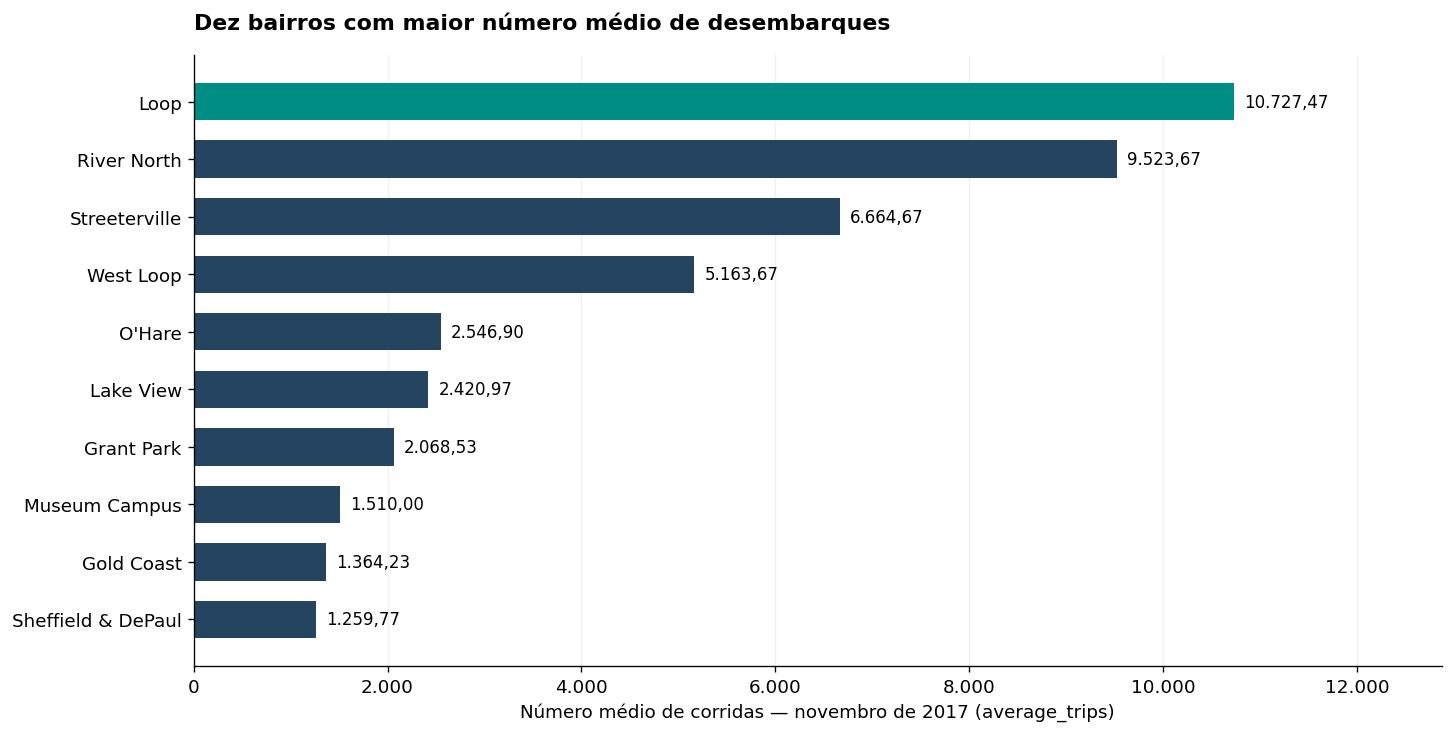

In [9]:
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
cores = [VERDE if nome == 'Loop' else AZUL for nome in top10_bairros.dropoff_location_name]
barras = ax.barh(top10_bairros.dropoff_location_name, top10_bairros.average_trips,
                 color=cores, height=0.65)
ax.invert_yaxis()
ax.set_title('Dez bairros com maior número médio de desembarques', loc='left')
ax.set_xlabel('Número médio de corridas — novembro de 2017 (average_trips)')
ax.set_ylabel('')
ax.set_xlim(0, top10_bairros.average_trips.max() * 1.2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: numero_pt(v)))
ax.grid(axis='x', alpha=0.18)
ax.set_axisbelow(True)
ax.bar_label(barras, labels=[numero_pt(v, 2) for v in top10_bairros.average_trips],
             padding=6, fontsize=10)
fig.savefig(RESULTADOS / 'bairros_top10.png', dpi=140, bbox_inches='tight')
plt.show()

In [10]:
soma_medias = bairros.average_trips.sum()
participacao_destinos_top10 = top10_bairros.average_trips.sum() / soma_medias
print(
    f'{top10_bairros.iloc[0].dropoff_location_name} lidera o ranking com média '
    f'{numero_pt(top10_bairros.iloc[0].average_trips, 2)}, seguido de '
    f'{top10_bairros.iloc[1].dropoff_location_name}, com '
    f'{numero_pt(top10_bairros.iloc[1].average_trips, 2)}.'
)
print(
    f'Os dez primeiros bairros representam '
    f'{numero_pt(100 * participacao_destinos_top10, 2)}% da soma das médias '
    f'dos {len(bairros)} bairros da base.'
)
posicao_ohare = int(bairros.index[bairros.dropoff_location_name.eq("O'Hare")][0]) + 1
print(f"O'Hare aparece na {posicao_ohare}ª posição, indicando volume relevante de viagens ao aeroporto.")
print(
    'Os destinos de maior volume oferecem uma referência para estudar o '
    'posicionamento da operação da Zuber. Para definir a disponibilidade de '
    'motoristas, também seriam necessários locais de embarque, horários e custos.'
)

Loop lidera o ranking com média 10.727,47, seguido de River North, com 9.523,67.
Os dez primeiros bairros representam 76,69% da soma das médias dos 94 bairros da base.
O'Hare aparece na 5ª posição, indicando volume relevante de viagens ao aeroporto.
Os destinos de maior volume oferecem uma referência para estudar o posicionamento da operação da Zuber. Para definir a disponibilidade de motoristas, também seriam necessários locais de embarque, horários e custos.


## Passo 5 — teste da hipótese sobre duração média

**Hipótese nula (H₀):** a duração média das corridas Loop → O'Hare é igual nos
grupos `Bad` e `Good` aos sábados: μBad = μGood.

**Hipótese alternativa (H₁):** as durações médias são diferentes: μBad ≠ μGood.
O teste é bilateral, pois a palavra “muda” permite diferença em qualquer direção.

Escolhemos **α = 0,05**. Usamos o **teste t de Welch para duas amostras**,
`stats.ttest_ind(..., equal_var=False, alternative='two-sided')`.
O critério compara médias, que são a medida solicitada. Welch permite variâncias
e tamanhos de amostra diferentes, sem exigir previamente igualdade de variâncias.
O teste pressupõe independência das observações; suas limitações são discutidas
ao final. O tamanho dos grupos favorece a aproximação usada para comparar médias.

Se p < α, rejeitamos H₀. Caso contrário, não rejeitamos H₀; isso não demonstra
que as médias sejam idênticas.

In [11]:
corridas_original = pd.read_csv(obter_arquivo(
    'project_sql_result_07.csv', URL_DATASETS + 'project_sql_result_07.csv'
))
corridas = corridas_original.copy()
corridas['start_ts'] = pd.to_datetime(corridas['start_ts'], errors='raise')
corridas['weather_conditions'] = corridas['weather_conditions'].astype('string').str.strip()
corridas['duration_seconds'] = pd.to_numeric(corridas['duration_seconds'], errors='raise')

print(f'Corridas recebidas: {len(corridas)}')
print('Tipos:', corridas.dtypes.astype(str).to_dict())
print('Ausentes:', corridas.isna().sum().to_dict())
repeticoes = int(corridas.duplicated().sum())
print(f'Linhas repetidas nas três colunas: {repeticoes}')
corridas.head()

Corridas recebidas: 1068
Tipos: {'start_ts': 'datetime64[ns]', 'weather_conditions': 'string', 'duration_seconds': 'float64'}
Ausentes: {'start_ts': 0, 'weather_conditions': 0, 'duration_seconds': 0}
Linhas repetidas nas três colunas: 197


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


In [12]:
if corridas.isna().any().any():
    raise ValueError('Há campos obrigatórios ausentes na base de corridas.')
if not set(corridas.weather_conditions.unique()).issubset({'Good', 'Bad'}):
    raise ValueError('Há categorias meteorológicas desconhecidas.')
if not corridas.start_ts.dt.dayofweek.eq(5).all():
    raise ValueError('Há corridas fora de sábado na base de teste.')
if not (
    corridas.start_ts.ge('2017-11-01') & corridas.start_ts.lt('2017-12-01')
).all():
    raise ValueError('Há corridas fora de novembro de 2017.')

# Confere a classificação do CSV contra a tabela meteorológica fornecida.
conferencia_clima = corridas.merge(
    clima[['ts', 'weather_conditions']], how='left',
    left_on='start_ts', right_on='ts', suffixes=('_csv', '_html'),
    validate='many_to_one'
)
if conferencia_clima.ts.isna().any():
    raise ValueError('Há corridas sem registro correspondente no HTML de clima.')
if conferencia_clima.weather_conditions_csv.ne(conferencia_clima.weather_conditions_html).any():
    raise ValueError('A classificação do CSV diverge da tabela de clima.')

duracoes_validas = np.isfinite(corridas.duration_seconds) & corridas.duration_seconds.gt(0)
quantidade_invalidas = int((~duracoes_validas).sum())
corridas_validas = corridas.loc[duracoes_validas].copy()
corridas_validas['duration_minutes'] = corridas_validas.duration_seconds / 60

print(f'Durações inválidas excluídas: {quantidade_invalidas}')
print(f'Corridas no teste principal: {len(corridas_validas)}')
print('As linhas repetidas foram mantidas no teste principal.')
print('Os valores positivos extremos também foram mantidos.')
print('Todas as corridas possuem clima disponível e classificação coerente com o HTML.')

Durações inválidas excluídas: 6
Corridas no teste principal: 1062
As linhas repetidas foram mantidas no teste principal.
Os valores positivos extremos também foram mantidos.
Todas as corridas possuem clima disponível e classificação coerente com o HTML.


**Decisões de preparação.** As seis durações zero não representam tempos
válidos para uma viagem entre esses locais e foram excluídas do teste principal.

Há 197 repetições nas três colunas recebidas. O horário foi arredondado e o
arquivo não inclui `trip_id`: corridas distintas podem ter a mesma hora, clima
e duração. Mantemos essas linhas no teste principal para não descartar viagens
legítimas. A maior duração positiva pode representar trânsito intenso; sem
evidência de erro, não foi excluída com base apenas no valor.

In [13]:
resumo_duracoes = corridas_validas.groupby('weather_conditions').agg(
    corridas=('duration_seconds', 'size'),
    media_segundos=('duration_seconds', 'mean'),
    mediana_segundos=('duration_seconds', 'median'),
    desvio_padrao_segundos=('duration_seconds', 'std'),
    menor_duracao_segundos=('duration_seconds', 'min'),
    maior_duracao_segundos=('duration_seconds', 'max'),
)
resumo_duracoes['media_minutos'] = resumo_duracoes.media_segundos / 60
resumo_duracoes

,corridas,media_segundos,mediana_segundos,desvio_padrao_segundos,menor_duracao_segundos,maior_duracao_segundos,media_minutos
weather_conditions,,,,,,,
Bad,180,2427.21,2540.0,721.31,480.0,4980.0,40.45
Good,882,2013.28,1800.0,743.57,60.0,7440.0,33.55


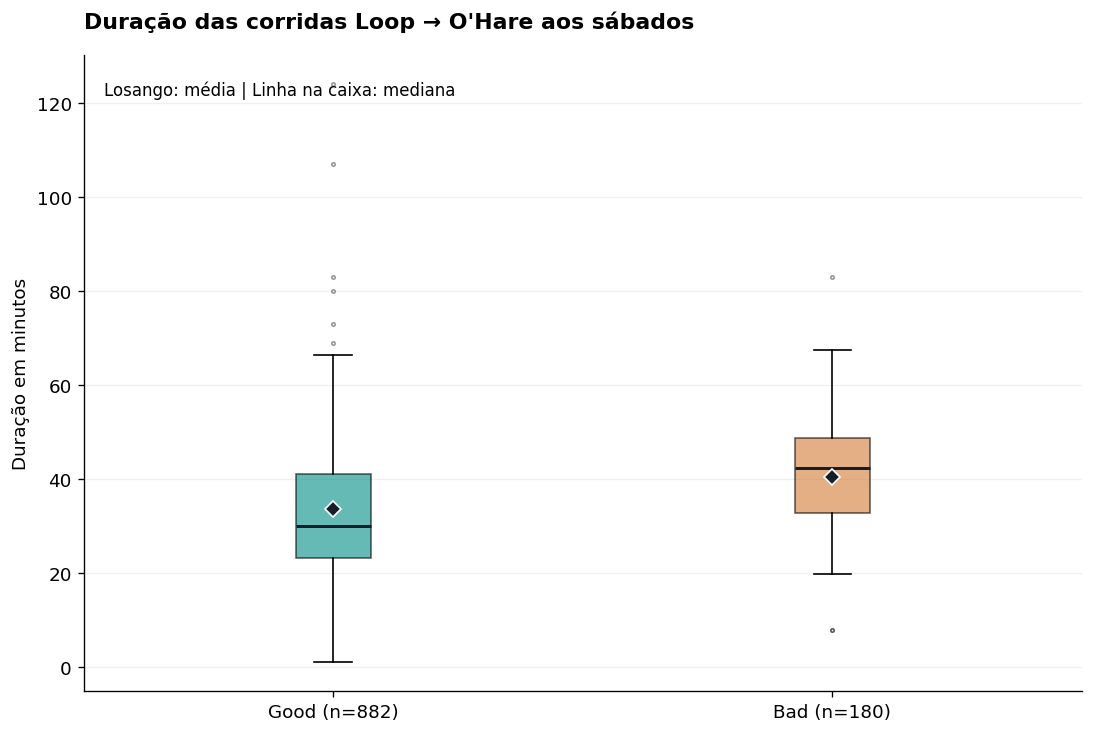

In [14]:
duracoes_good = corridas_validas.loc[
    corridas_validas.weather_conditions.eq('Good'), 'duration_seconds'
]
duracoes_bad = corridas_validas.loc[
    corridas_validas.weather_conditions.eq('Bad'), 'duration_seconds'
]
fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
caixas = ax.boxplot([duracoes_good / 60, duracoes_bad / 60],
                    patch_artist=True, showmeans=True,
                    meanprops={'marker': 'D', 'markerfacecolor': '#161f29',
                               'markeredgecolor': 'white', 'markersize': 7},
                    medianprops={'color': '#161f29', 'linewidth': 1.8},
                    flierprops={'marker': '.', 'markersize': 4, 'alpha': 0.4})
for caixa, cor in zip(caixas['boxes'], [VERDE, LARANJA]):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.6)
ax.set_xticks([1, 2], [f'Good (n={len(duracoes_good)})', f'Bad (n={len(duracoes_bad)})'])
ax.set_title("Duração das corridas Loop → O'Hare aos sábados", loc='left')
ax.set_ylabel('Duração em minutos')
ax.grid(axis='y', alpha=0.18)
ax.text(0.02, 0.96, 'Losango: média | Linha na caixa: mediana',
         transform=ax.transAxes, va='top', fontsize=10)
fig.savefig(RESULTADOS / 'duracao_por_clima.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
if min(len(duracoes_bad), len(duracoes_good)) < 2:
    raise ValueError('Cada grupo precisa de pelo menos duas corridas.')
teste = stats.ttest_ind(
    duracoes_bad, duracoes_good,
    equal_var=False, alternative='two-sided', nan_policy='raise'
)
if not np.isfinite(teste.pvalue):
    raise ValueError('O teste não produziu um p-valor válido.')

diferenca_segundos = duracoes_bad.mean() - duracoes_good.mean()
diferenca_percentual = 100 * diferenca_segundos / duracoes_good.mean()
intervalo = teste.confidence_interval(confidence_level=1 - ALFA)
print(f'Alfa: {ALFA}')
print(f'Estatística t: {teste.statistic:.6f}')
print(f'Graus de liberdade de Welch: {teste.df:.3f}')
print(f'p-valor bilateral: {teste.pvalue:.6e}')
print(f'Média Good: {numero_pt(duracoes_good.mean(), 2)} s '
      f'({numero_pt(duracoes_good.mean() / 60, 2)} min)')
print(f'Média Bad: {numero_pt(duracoes_bad.mean(), 2)} s '
      f'({numero_pt(duracoes_bad.mean() / 60, 2)} min)')
print(f'Diferença Bad − Good: {numero_pt(diferenca_segundos, 2)} s '
      f'({numero_pt(diferenca_segundos / 60, 2)} min; '
      f'{numero_pt(diferenca_percentual, 2)}%)')
print(f'IC de 95% para a diferença: '
      f'[{numero_pt(intervalo.low / 60, 2)}; {numero_pt(intervalo.high / 60, 2)}] min')
if teste.pvalue < ALFA:
    print('Decisão: rejeitar H₀. Há evidência de diferença entre as médias, '
          'sob as premissas do teste por corrida.')
else:
    print('Decisão: não rejeitar H₀. Não há evidência suficiente de diferença '
          'entre as médias ao nível de significância escolhido.')

Alfa: 0.05
Estatística t: 6.979329
Graus de liberdade de Welch: 262.548
p-valor bilateral: 2.417359e-11
Média Good: 2.013,28 s (33,55 min)
Média Bad: 2.427,21 s (40,45 min)
Diferença Bad − Good: 413,93 s (6,90 min; 20,56%)
IC de 95% para a diferença: [4,95; 8,85] min
Decisão: rejeitar H₀. Há evidência de diferença entre as médias, sob as premissas do teste por corrida.


In [16]:
print(
    'Interpretação do gráfico: a distribuição de Bad está deslocada para '
    'durações maiores nesta amostra. Há sobreposição entre os grupos e valores '
    'extremos em ambos. O teste e o intervalo de confiança quantificam a '
    'diferença entre as médias, que o boxplot sozinho não comprova.'
)

Interpretação do gráfico: a distribuição de Bad está deslocada para durações maiores nesta amostra. Há sobreposição entre os grupos e valores extremos em ambos. O teste e o intervalo de confiança quantificam a diferença entre as médias, que o boxplot sozinho não comprova.


### Sensibilidade às decisões de preparação

Repetimos Welch com todos os registros e, como cenário exploratório, após
retirar também as linhas repetidas. A retirada de repetições pode excluir
corridas legítimas; esse cenário não substitui o teste principal. A comparação
verifica se as decisões de preparação mudam a conclusão convencional por corrida.

In [17]:
cenarios = {
    'Original (inclui duração zero)': corridas,
    'Principal (somente duração positiva)': corridas_validas,
    'Exploratório (positivas sem linhas repetidas)': corridas_validas.drop_duplicates(
        subset=['start_ts', 'weather_conditions', 'duration_seconds']
    ),
}
sensibilidade = []
for nome, dados in cenarios.items():
    bad = dados.loc[dados.weather_conditions.eq('Bad'), 'duration_seconds']
    good = dados.loc[dados.weather_conditions.eq('Good'), 'duration_seconds']
    resultado = stats.ttest_ind(bad, good, equal_var=False, alternative='two-sided')
    sensibilidade.append({
        'cenário': nome,
        'n_Bad': len(bad), 'n_Good': len(good),
        'média_Bad_min': bad.mean() / 60,
        'média_Good_min': good.mean() / 60,
        'p_valor': resultado.pvalue,
        'rejeita_H0': bool(resultado.pvalue < ALFA),
    })
sensibilidade = pd.DataFrame(sensibilidade)
print(sensibilidade.to_string(index=False, formatters={'p_valor': lambda x: f'{x:.6e}'}))

                                      cenário  n_Bad  n_Good  média_Bad_min  média_Good_min      p_valor  rejeita_H0
               Original (inclui duração zero)    180     888          40.45           33.33 6.738994e-12        True
         Principal (somente duração positiva)    180     882          40.45           33.55 2.417359e-11        True
Exploratório (positivas sem linhas repetidas)    148     717          40.15           34.15 2.859196e-07        True


### Dependência por horário e alcance da conclusão

Corridas que começam na mesma hora compartilham clima e parte das condições de
trânsito. Isso pode violar a independência pressuposta pelo teste por corrida.
A base abrange somente quatro sábados e `Bad` ocorre em dois deles.

A verificação abaixo compara as **médias por hora**, atribuindo o mesmo peso a
cada horário. Ela reduz a repetição de observações na mesma hora, mas testa uma
média diferente da média por corrida: horários com poucas viagens passam a ter
o mesmo peso dos horários mais movimentados. Horários de um mesmo dia ainda
podem ser dependentes.

In [18]:
medias_horarias = corridas_validas.groupby(['start_ts', 'weather_conditions']).agg(
    media_segundos=('duration_seconds', 'mean'),
    corridas=('duration_seconds', 'size'),
).reset_index()
horas_bad = medias_horarias.loc[medias_horarias.weather_conditions.eq('Bad'), 'media_segundos']
horas_good = medias_horarias.loc[medias_horarias.weather_conditions.eq('Good'), 'media_segundos']
teste_horario = stats.ttest_ind(horas_bad, horas_good, equal_var=False, alternative='two-sided')
print(f'Sábados observados: {corridas_validas.start_ts.dt.date.nunique()}')
print(f'Sábados com Bad: {corridas_validas.loc[corridas_validas.weather_conditions.eq("Bad"), "start_ts"].dt.date.nunique()}')
print(f'Horas Bad: {len(horas_bad)} | Horas Good: {len(horas_good)}')
print(f'p-valor da comparação de médias por hora: {teste_horario.pvalue:.6f}')
print('Esta verificação não substitui o teste solicitado de média por corrida.')

Sábados observados: 4
Sábados com Bad: 2
Horas Bad: 13 | Horas Good: 67
p-valor da comparação de médias por hora: 0.442475
Esta verificação não substitui o teste solicitado de média por corrida.


**Limite prático.** Welch por corrida encontra diferença significativa. A
comparação exploratória por hora não rejeita igualdade de médias ao nível de
5%. Como ela altera os pesos e a medida comparada, não constitui uma refutação
automática do primeiro teste. A diferença entre os resultados mostra que a
conclusão depende da unidade de análise e das premissas de independência.

Os dados são observacionais: horário de saída, trânsito, data, demanda do
aeroporto e outras características podem explicar parte da diferença.
O resultado não identifica um efeito causal da chuva, nem uma mudança na
frequência das viagens. Uma validação operacional exigiria mais datas e uma
análise que considerasse a dependência entre corridas do mesmo horário e dia.

## Conclusão do projeto

A amostra de 15 e 16 de novembro apresenta concentração de corridas nas maiores
empresas, com Flash Cab na liderança. No ranking de destinos, Loop e River North
ocupam as primeiras posições e O'Hare aparece entre os cinco primeiros bairros.

Na comparação solicitada por corrida, rejeitamos a hipótese de igualdade das
durações médias a 5%. As corridas classificadas como `Bad` têm média maior na
amostra. Os três cenários de preparação mantêm essa decisão. A verificação por
hora e a presença de apenas quatro sábados limitam uma interpretação mais ampla.

Para a Zuber, os resultados servem para aprofundar o estudo dos destinos de
maior volume e dos tempos necessários para atender viagens ao aeroporto.

In [19]:
import sys
import scipy
import matplotlib
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('Matplotlib:', matplotlib.__version__)

Python: 3.12.14
pandas: 2.2.3
NumPy: 2.3.5
SciPy: 1.17.0
Matplotlib: 3.10.8
